# Reducción de dimensionalidad — Análisis de Componentes Principales (PCA)

In [12]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
import sys
import os
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


sys.path.append(r'C:/Users/Pc/Desktop/practica_5/config')

from rutas import RUTA_DATOS_CRUDOS

ruta_raiz = os.path.abspath('..')
if ruta_raiz not in sys.path:
    sys.path.append(ruta_raiz)

from src.cleaning.limpiado import casteo_datos
from src.cleaning.limpiado import limpieza_imputacion
from notebooks.dimension import dimensionalidad

In [4]:
df_casteado= casteo_datos(RUTA_DATOS_CRUDOS)


c:\Users\Pc\Desktop\practica_5\src\cleaning\limpiado.py:5: DtypeWarning: Columns (0: Global_active_power, 1: Global_reactive_power, 2: Voltage, 3: Global_intensity, 4: Sub_metering_1, 5: Sub_metering_2) have mixed types. Specify dtype option on import or set low_memory=False.
  df_casteado= pd.read_csv(RUTA_DATOS_CRUDOS,sep=';')
c:\Users\Pc\Desktop\practica_5\src\cleaning\limpiado.py:7: UserWarning: Parsing dates in %d/%m/%Y %H:%M:%S format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df_casteado['Date-time'] = pd.to_datetime(df_casteado['Date'].astype(str) + ' ' + df_casteado['Time'].astype(str))


In [5]:
df_limpio=limpieza_imputacion(df_casteado)

In [6]:
df_limpio = dimensionalidad(df_limpio)

In [7]:
df_limpio.describe().T

,count,mean,std,min,25%,50%,75%,max
Global_active_power,2075259.0,1.419949e-16,1.0,-0.963569,-0.741268,-0.452467,0.415836,9.530169
Global_reactive_power,2075259.0,-6.661491e-17,1.0,-1.099893,-0.672920,-0.210366,0.625789,11.264526
Voltage,2075259.0,-3.141419e-15,1.0,-5.445978,-0.569154,0.051645,0.629205,4.113092
Sub_metering_1,2075259.0,-2.892490e-17,1.0,-0.181412,-0.181412,-0.181412,-0.181412,14.207450
Sub_metering_2,2075259.0,-7.012096e-18,1.0,-0.222795,-0.222795,-0.222795,-0.049982,13.602222
Sub_metering_3,2075259.0,-4.207258e-17,1.0,-0.765505,-0.765505,-0.646682,1.254491,2.918017


Verificamos que nuestras variables estan estandarizadas antes de hacer PCA, ya que para realizarlo es necesario que nuestros datos esten estandarizados. 

Nuestra meta sera conservar el 80% de la varianza

In [69]:
pca = PCA(n_components=0.8)

datos_pca = pca.fit_transform(df_limpio)


nombres_columnas = [f'Componente_{i+1}' for i in range(datos_pca.shape[1])]
df_pca = pd.DataFrame(datos_pca, columns=nombres_columnas)

varianza_por_componente = pca.explained_variance_ratio_
varianza_total = sum(varianza_por_componente)



print(f"Número de componentes seleccionados: {pca.n_components_}")
print(f"Varianza explicada por cada componente: {varianza_por_componente}")

print(f"Varianza total explicada: {varianza_total * 100:.2f}%")



Número de componentes seleccionados: 4
Varianza explicada por cada componente: [0.38529209 0.16467295 0.15536236 0.14117004]
Varianza total explicada: 84.65%


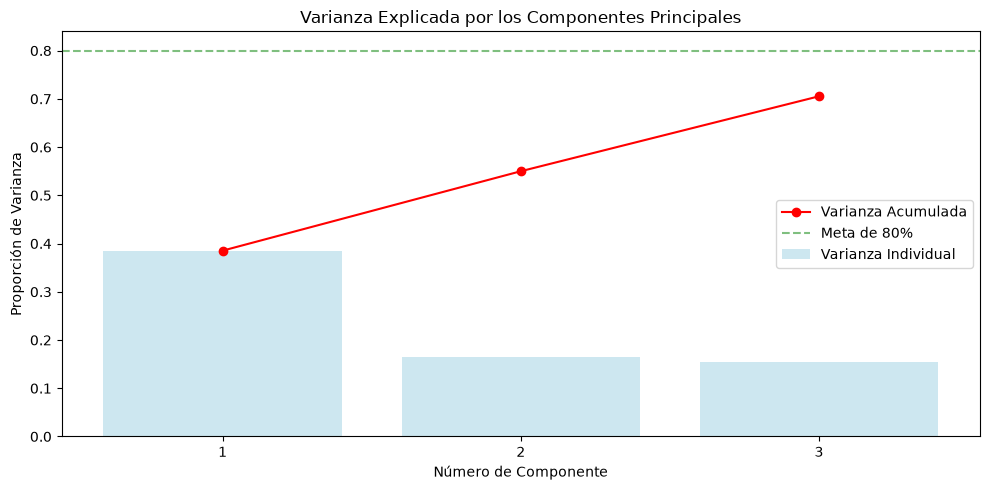

In [68]:
plt.figure(figsize=(10, 5))
varianza_acumulada = np.cumsum(varianza_por_componente)
componentes = range(1, len(varianza_por_componente) + 1)
plt.bar(componentes, varianza_por_componente, alpha=0.6, color='lightblue', label='Varianza Individual')
plt.plot(componentes, varianza_acumulada, marker='o', color='r', label='Varianza Acumulada')
plt.title('Varianza Explicada por los Componentes Principales')
plt.xlabel('Número de Componente')
plt.ylabel('Proporción de Varianza')
plt.xticks(componentes)
plt.axhline(y=0.8, color='green', linestyle='--', alpha=0.5, label='Meta de 80%') 
plt.legend()
plt.tight_layout()
plt.show()

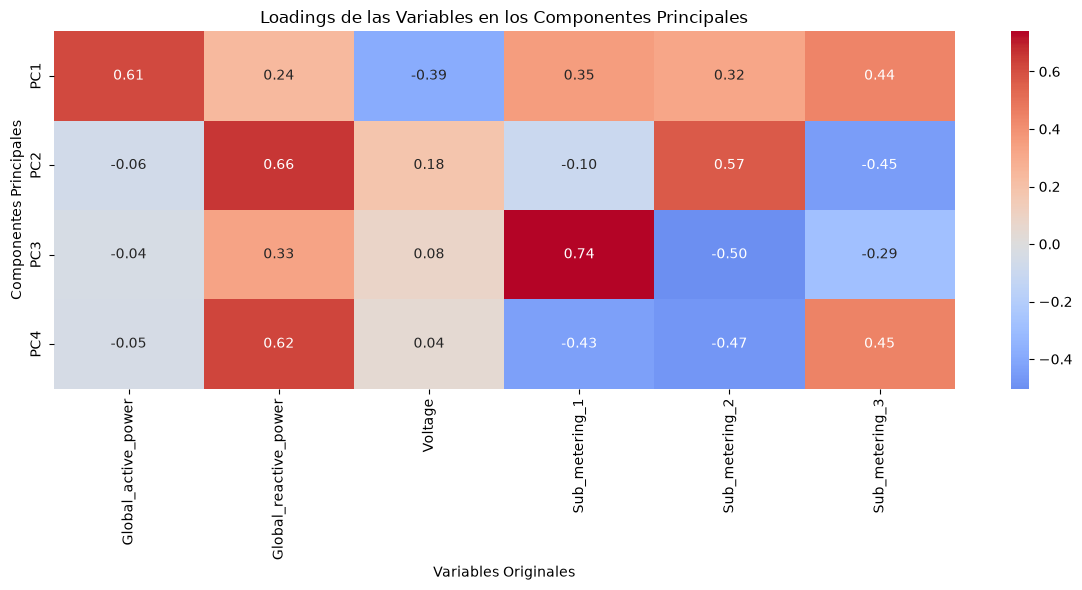

In [ ]:


pesos = pca.components_


columnas_originales = df_limpio.columns 
df_pesos = pd.DataFrame(
    pesos, 
    columns=columnas_originales, 
    index=['PC1', 'PC2', 'PC3', 'PC4']
)


plt.figure(figsize=(12, 6))
sns.heatmap(df_pesos, cmap='coolwarm', annot=True, fmt=".2f", center=0)
plt.title('Loadings de las Variables en los Componentes Principales')
plt.xlabel('Variables Originales')
plt.ylabel('Componentes Principales')
plt.tight_layout()
plt.show()